# 02 · Train/validation/test split and NEWS2 baseline

1. Make one fixed, stratified train / validation / test split that every later notebook reuses.
2. Score every visit with NEWS2 (`../src/news2.py`).
3. Measure how well NEWS2 agrees with the experts' triage level (`ktas_expert`), and what the missing-data safety rule adds.

NEWS2 is a fixed formula, so nothing is trained here. The **development set (train + val)** is only used to
look at cut-offs; the **test set** is kept for the numbers you report, so the later classifier can be compared on exactly the same patients.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

import ktas_data as kd
import news2

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
FIG_DIR = Path.cwd().parent / "figures"
FIG_DIR.mkdir(exist_ok=True)

## 1. Stratified split (70 / 15 / 15)

Stratified by `ktas_expert` so the rare KTAS 1 group appears in every part. Seed 42, saved to `splits.csv`.

In [2]:
df = kd.load_clean()
if "split" in df.columns:          # rerun: rebuild the split from scratch
    df = df.drop(columns="split")
splits = kd.make_splits(df, seed=42)
splits.to_csv(kd.PROCESSED_DIR / "splits.csv", index=False)
df = df.merge(splits, on="visit_id", validate="one_to_one")

pd.crosstab(df.ktas_expert, df.split, margins=True)[["train", "val", "test", "All"]]

split,train,val,test,All
ktas_expert,,,,
1,18,3,4,25
2,158,29,33,220
3,346,66,73,485
4,304,84,69,457
5,56,8,11,75
All,882,190,190,1262


KTAS 1 has only 4 patients in the test set, so test-set numbers for KTAS 1 alone are very noisy.
Results are therefore shown for the test set **and** for all visits (fair here, since NEWS2 learns nothing from the data).

## 2. Score every visit

In [3]:
scores = news2.score_frame(df)
df = pd.concat([df, scores], axis=1)
df[["visit_id", "ktas_expert", "news2", "risk", "risk_safe", "floor_priority", "note"]].sample(6, random_state=1)

,visit_id,ktas_expert,news2,risk,risk_safe,floor_priority,note
1180,1181,2,1,low,low,5,NEWS2 1 = LOW risk. Abnormal: Temp 36 °C (+1). Not recorded: SpO2. Score may be underestimated by up to 3.
255,256,4,2,low,low,5,"NEWS2 2 = LOW risk. Abnormal: SBP 101 mmHg (+1), Temp 36 °C (+1). Not recorded: SpO2. Score may be underestimated by up to 3."
304,305,4,0,low,low,5,NEWS2 0 = LOW risk. All recorded vitals in normal range. Not recorded: SpO2. Score may be underestimated by up to 3.
403,404,2,6,medium,medium,3,"NEWS2 6 = MEDIUM risk. Abnormal: RR 22/min (+2), SBP 100 mmHg (+2), HR 99 bpm (+1), Temp 36 °C (+1)."
75,76,3,2,low,low,5,"NEWS2 2 = LOW risk. Abnormal: SBP 110 mmHg (+1), Temp 36 °C (+1)."
119,120,2,1,low,low,5,NEWS2 1 = LOW risk. Abnormal: HR 50 bpm (+1). Not recorded: SpO2. Score may be underestimated by up to 3.


Example of the full output the main language model would receive for one patient:

In [4]:
example = news2.score(rr=22, spo2=89, sbp=118, hr=124, temp_c=37.0, consciousness="alert")
print(news2.note(example))
example

NEWS2 7 = HIGH risk. Abnormal: SpO2 89% (+3), RR 22/min (+2), HR 124 bpm (+2).


{'news2': 7,
 'subscores': {'rr': 2,
  'spo2': 3,
  'sbp': 0,
  'hr': 2,
  'temp_c': 0,
  'consciousness': 0,
  'on_oxygen': 0},
 'risk': 'high',
 'risk_safe': 'high',
 'escalated': False,
 'escalation_reason': '',
 'missing': [],
 'assumed': ['on_oxygen'],
 'floor_priority': 2,
 'values': {'rr': 22,
  'spo2': 89,
  'sbp': 118,
  'hr': 124,
  'temp_c': 37.0,
  'consciousness': 'alert'}}

## 3. Does NEWS2 rise with urgency?

In [5]:
by_level = df.groupby("ktas_expert").news2.agg(["count", "mean", "median"]).round(2)
by_level["% NEWS2 >= 5"] = df.groupby("ktas_expert").news2.apply(lambda s: (s >= 5).mean() * 100).round(1)
rho, p = spearmanr(df.news2, df.ktas_expert)
print(f"Spearman rho (NEWS2 vs KTAS, all visits) = {rho:.2f}, p = {p:.1e}   (negative = higher score, more urgent)")
by_level

Spearman rho (NEWS2 vs KTAS, all visits) = -0.25, p = 6.7e-20   (negative = higher score, more urgent)


,count,mean,median,% NEWS2 >= 5
ktas_expert,,,,
1,25,5.16,3.0,48.0
2,220,2.48,2.0,18.6
3,485,1.29,1.0,4.1
4,457,0.91,1.0,0.9
5,75,1.04,1.0,0.0


## 4. How well does NEWS2 pick out urgent patients?

Two definitions of "urgent":
- **KTAS 1–2** (resuscitation / emergent): the patients who must never wait.
- **KTAS 1–3**: the dataset's own "emergency" group.

AUROC = chance that a random urgent patient scores higher than a random non-urgent one (0.5 = coin flip). 95% CIs from 2,000 bootstrap resamples.

In [6]:
def auroc_ci(y, s, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            stats.append(roc_auc_score(y[i], s[i]))
    return roc_auc_score(y, s), *np.percentile(stats, [2.5, 97.5])

# Ordinal score for the safety-extended bands, so it can be ranked like NEWS2
df["risk_safe_rank"] = df.risk_safe.cat.codes

rows = []
for subset, d in [("test", df[df.split == "test"]), ("all visits", df)]:
    for label, cut in [("KTAS 1-2", 2), ("KTAS 1-3", 3)]:
        y = (d.ktas_expert <= cut).astype(int)
        for name, s in [("NEWS2 score", d.news2), ("risk band (safe)", d.risk_safe_rank)]:
            auc, lo, hi = auroc_ci(y, s)
            rows.append({"data": subset, "urgent =": label, "score": name, "n urgent": y.sum(),
                         "AUROC": round(auc, 3), "95% CI": f"{lo:.2f}-{hi:.2f}"})
pd.DataFrame(rows)

,data,urgent =,score,n urgent,AUROC,95% CI
0,test,KTAS 1-2,NEWS2 score,37,0.694,0.58-0.79
1,test,KTAS 1-2,risk band (safe),37,0.682,0.60-0.76
2,test,KTAS 1-3,NEWS2 score,110,0.630,0.55-0.70
3,test,KTAS 1-3,risk band (safe),110,0.578,0.54-0.62
4,all visits,KTAS 1-2,NEWS2 score,245,0.691,0.65-0.73
5,all visits,KTAS 1-2,risk band (safe),245,0.677,0.65-0.71
6,all visits,KTAS 1-3,NEWS2 score,730,0.606,0.58-0.64
7,all visits,KTAS 1-3,risk band (safe),730,0.577,0.56-0.59


The raw NEWS2 score ranks patients better than the four risk bands, because the bands merge many scores into
one group. The bands are not meant for ranking: their job is to set the safety floor (section 6).

### Cut-offs (development set only)

Sensitivity = share of urgent (KTAS 1–2) patients flagged. Specificity = share of non-urgent patients not flagged.
The official NEWS2 trigger points are **5** (urgent review) and **7** (emergency response).

In [7]:
dev = df[df.split != "test"]
y = dev.ktas_expert <= 2
rows = []
for t in range(1, 9):
    flag = dev.news2 >= t
    rows.append({"NEWS2 >=": t, "flagged": flag.sum(),
                 "sensitivity": round((flag & y).sum() / y.sum(), 2),
                 "specificity": round((~flag & ~y).sum() / (~y).sum(), 2),
                 "PPV": round((flag & y).sum() / max(flag.sum(), 1), 2)})
pd.DataFrame(rows)

,NEWS2 >=,flagged,sensitivity,specificity,PPV
0,1,659,0.77,0.42,0.24
1,2,378,0.57,0.70,0.31
2,3,206,0.47,0.87,0.47
3,4,104,0.30,0.95,0.61
4,5,63,0.21,0.98,0.68
5,6,41,0.15,0.99,0.76
6,7,29,0.10,0.99,0.72
7,8,19,0.06,0.99,0.68


Even at the lowest cut-offs NEWS2 misses a large share of KTAS 1–2 patients: many emergencies (chest pain,
stroke, severe pain) present with normal vitals. This is the evidence that vitals alone cannot triage, and why
the main language model must combine this note with the patient's history and the image findings.

## 5. Risk band vs expert triage level

Rows = NEWS2 band, columns = expert KTAS. Left: standard NEWS2. Right: with the safety extension.

In [8]:
std = pd.crosstab(df.risk, df.ktas_expert, dropna=False)
safe = pd.crosstab(df.risk_safe, df.ktas_expert, dropna=False)
pd.concat({"standard NEWS2": std, "with safety extension": safe}, axis=1)

standard NEWS2                    with safety extension                   
ktas_expert              1    2    3    4   5                     1    2    3    4   5
low                      3  148  447  446  70                     1  145  447  445  68
low-medium              10   31   18    7   5                     0   30   18    7   4
medium                   2   25   11    4   0                     1   25   11    4   0
high                    10   16    9    0   0                    23   20    9    1   3

In [9]:
k1 = df[df.ktas_expert == 1]
print(f"KTAS 1 patients (n = {len(k1)}) rated LOW risk:")
print(f"  standard NEWS2       : {(k1.risk == 'low').sum()}")
print(f"  with safety extension: {(k1.risk_safe == 'low').sum()}")
print(f"Visits escalated by the extension: {df.escalated.sum()}, "
      f"of which KTAS 1-2: {(df.escalated & (df.ktas_expert <= 2)).sum()}")
df.loc[df.escalated, ["visit_id", "split", "ktas_expert", "mental_label", "n_missing", "news2", "risk", "risk_safe"]]

KTAS 1 patients (n = 25) rated LOW risk:
  standard NEWS2       : 3
  with safety extension: 1
Visits escalated by the extension: 21, of which KTAS 1-2: 17


,visit_id,split,ktas_expert,mental_label,n_missing,news2,risk,risk_safe
121,122,train,1,alert,5,0,low,high
149,150,train,1,pain,5,3,low-medium,high
154,155,train,1,unresponsive,5,3,low-medium,high
160,161,train,1,pain,3,5,medium,high
179,180,train,2,alert,5,0,low,high
189,190,train,2,alert,3,1,low,high
214,215,test,1,unresponsive,1,3,low-medium,high
353,354,train,5,verbal,5,3,low-medium,high
426,427,train,4,alert,5,0,low,high
702,703,train,1,alert,5,0,low,high


## 6. The safety floor

`floor_priority` is the least urgent priority the main model may give a patient (high → 2, medium or a single
parameter scoring 3 → 3, low → no limit). Because it only ever makes a patient *more* urgent, it cannot cause
under-triage. Two questions:

- **Cost:** how often does the floor force a patient above the experts' level (over-triage)?
- **Coverage:** how many urgent patients get no floor at all, so the main model alone must catch them?

In [10]:
rows = []
for subset, d in [("test", df[df.split == "test"]), ("all visits", df)]:
    urgent = d.ktas_expert <= 2
    rows.append({
        "data": subset,
        "visits": len(d),
        "floor applied (< 5)": int((d.floor_priority < 5).sum()),
        "floor over-triages (floor < expert KTAS)": int((d.floor_priority < d.ktas_expert).sum()),
        "urgent (KTAS 1-2)": int(urgent.sum()),
        "urgent with a floor": int((urgent & (d.floor_priority <= 3)).sum()),
        "urgent with NO floor": int((urgent & (d.floor_priority == 5)).sum()),
    })
pd.DataFrame(rows).set_index("data").T

data,test,all visits
visits,190,1262
floor applied (< 5),22,156
floor over-triages (floor < expert KTAS),3,28
urgent (KTAS 1-2),37,245
urgent with a floor,15,99
urgent with NO floor,22,146


## 7. Figure for the report

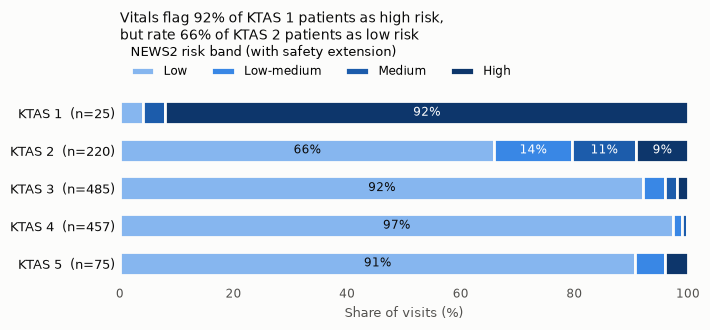

In [11]:
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # ordinal blue: low -> high
LABELS = {"low": "Low", "low-medium": "Low-medium", "medium": "Medium", "high": "High"}

share = pd.crosstab(df.ktas_expert, df.risk_safe, normalize="index", dropna=False)[news2.RISK_ORDER] * 100
counts = df.ktas_expert.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7.2, 3.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
y = np.arange(len(share))[::-1]
left = np.zeros(len(share))
for band, color in zip(news2.RISK_ORDER, COLORS):
    vals = share[band].to_numpy()
    ax.barh(y, vals, left=left, color=color, height=0.62, edgecolor=SURFACE, linewidth=2, label=LABELS[band])
    for yi, l, v in zip(y, left, vals):
        if v >= 9:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                    color=INK if color == COLORS[0] else "white")
    left += vals

ax.set_yticks(y, [f"KTAS {k}  (n={counts[k]})" for k in share.index], color=INK, fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of visits (%)", color=MUTED, fontsize=9)
ax.tick_params(axis="x", colors=MUTED, labelsize=8.5, length=0)
ax.tick_params(axis="y", length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(title="NEWS2 risk band (with safety extension)", ncols=4, loc="lower left", bbox_to_anchor=(0, 1.02),
          frameon=False, fontsize=8.5, title_fontsize=9, alignment="left")
pct = lambda k, band: share.loc[k, band]
TITLE = (f"Vitals flag {pct(1, 'high'):.0f}% of KTAS 1 patients as high risk,\n"
         f"but rate {pct(2, 'low'):.0f}% of KTAS 2 patients as low risk")
ax.set_title(TITLE, loc="left", fontsize=10, color=INK, pad=38)
fig.tight_layout()
fig.savefig(FIG_DIR / "news2_risk_by_ktas.png", dpi=300, facecolor=SURFACE)
plt.show()

## 8. Save scores

In [12]:
cols = ["visit_id", "split", "ktas_expert", "news2", "risk", "risk_safe", "escalated",
        "floor_priority", "n_missing", "note"]
df[cols].to_csv(kd.PROCESSED_DIR / "news2_scores.csv", index=False, encoding="utf-8-sig")
print("Saved:", sorted(p.name for p in kd.PROCESSED_DIR.iterdir()))
print("Figure:", sorted(p.name for p in FIG_DIR.iterdir()))

Saved: ['cleaning_log.csv', 'ktas_clean.csv', 'news2_scores.csv', 'splits.csv', 'test_predictions.csv']
Figure: ['feature_importance.png', 'news2_risk_by_ktas.png', 'roc_test.png']


## Summary for the report

(Numbers from the run of 18 Oct 2026, split seed 42. Re-check them if the data or rules change.)

- **NEWS2 rises with urgency but discriminates only modestly.** Mean score 5.2 for KTAS 1 versus about 1 for KTAS 4–5
  (Spearman ρ = −0.25). AUROC for spotting KTAS 1–2 = 0.69 on the test set (95% CI 0.58–0.79), 0.69 on all visits.
- **Vitals alone miss most urgent patients.** At the official trigger (NEWS2 ≥ 5) only 21% of KTAS 1–2 patients are
  flagged (development set); even NEWS2 ≥ 1 misses 23%.
- **The safety extension fixes the cardiac-arrest problem.** KTAS 1 patients rated high: 10 of 25 with standard NEWS2,
  23 of 25 with the extension. Cost: 21 visits escalated, 4 of them KTAS 4–5 (vitals simply not taken).
- **The floor never causes under-triage.** It over-triages 28 of 1,262 visits (2.2%). 146 of 245 urgent patients (60%)
  get no floor, so the main language model must catch them from history and images. This is the case for the multimodal design.

**Next notebook:** a small classifier (vitals + age + consciousness + pain → KTAS level) trained on `train`, tuned on
`val`, compared with NEWS2 and the triage nurse on `test`.